# Pearson, Spearman and mutual information — 2026-10-15

A revised analysis and figure notebook using the completed **2026-09-24 focused extraction (pyspi computation r7)**: 50 independent MTS instances per condition, 350 recordings. The notebook date is the analysis date; no new extraction is implied.

The question is how a change in channel-to-channel functional form changes agreement between dependence statistics. Follow one mixed recording from its shared mother and channel construction, through individual edges and SPI matrices, to the SPI–SPI plane. Then check the pattern across independent recordings and quantify the effect of mixing pair types.

In [1]:
from pathlib import Path
import sys, json
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.cases.refresh_case_figures import (
    analyze, plot_pair_rainclouds, plot_rmi_channel_pairs,
    plot_mi_sensitivity, plot_spi_planes, plot_dtw_pair_sweep,
)
DATA = ROOT / 'data/cases/r-rho-mi-260924/data'
OUT = ROOT / 'results/cases/r-rho-mi-261015'
# Reanalyse the archived focused SPIs; do not recompute or mix computation versions.
frame = analyze(DATA, 'r-rho-mi', OUT)
audit = json.loads((OUT / 'audit.json').read_text())
print(f"{audit['datasets']} datasets; {len(audit['spis'])} focused SPIs; {audit['nonfinite_off_diagonal_values']} nonfinite off-diagonal values")
from research.cases.case_mechanisms import (plot_rmi_construction, plot_rmi_matrices, analyze_rmi_composition, plot_rmi_composition)

350 datasets; 4 focused SPIs; 0 nonfinite off-diagonal values


Construction: one AR(1) mother, $s_t=0.8s_{t-1}+\epsilon_t$, is standardised to $u_t$. Channels observe $g(u)=u$ (L), $g(u)=1/(1+e^{-\beta u})$ (M), or $g(u)=u^2$ (Q). Each transformed signal is standardised before independent Gaussian measurement noise, and again afterwards. Noise standard deviations are $0.01\,\kappa_i$, with $\kappa_i\sim\mathrm{Geom}(1/5)$. This variation supplies a nonconstant profile of pair strengths; equal clean signal variance does not make estimation equally easy for every transform.

The channel counts (L,M,Q) are (32,0,0), (16,16,0), and (12,12,8), with $T=2000$ and $\beta\in\{\pi,5,2\pi\}$. Within a mixture, beta variants share mother/noise draws; mixtures use independent seeds. The all-linear baseline is computed once. These existing data remain useful; a future construction need not use this large M or T.

The fixed example below is instance 0 of the L/M/Q mixture at beta 5. A common window, samples 100–249, shows the mother and all 32 observed channels; heatmap colours saturate outside ±3 SD. Family boundaries follow the generating channel order. Replaying the stored seed must reproduce the archived observation within floating-point tolerance before the mother is displayed.

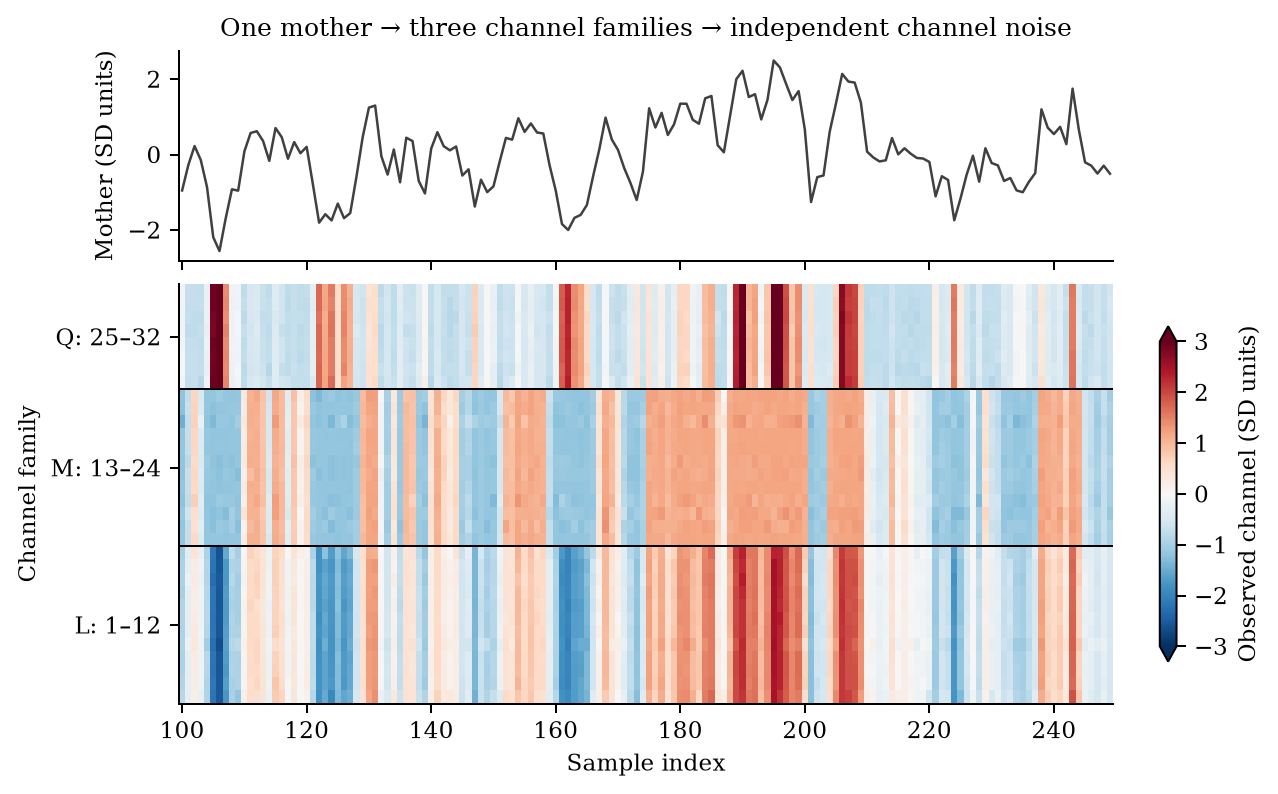

In [2]:
fig = plot_rmi_construction(frame, OUT)
plt.show()

The mechanism is visible in raw channel pairs. Pearson measures linear association without requiring Gaussian data; Spearman correlates ranks and is invariant to strictly increasing noiseless transforms. Noise and sigmoid saturation can still change ranks. The quadratic transform folds the relationship and can leave MI detectable while signed linear/rank correlations are small. The examples below are fixed in advance: instance 0, beta 5, first linear channel against the next linear channel and the first channels of each other family. Values are the archived estimates, with MI in nats.

Edges A, B and C are channels 1–2 (L–L), 1–13 (L–M), and 1–25 (L–Q). These same edges are labelled in the matrix and SPI–SPI views, avoiding a change of example between explanations.

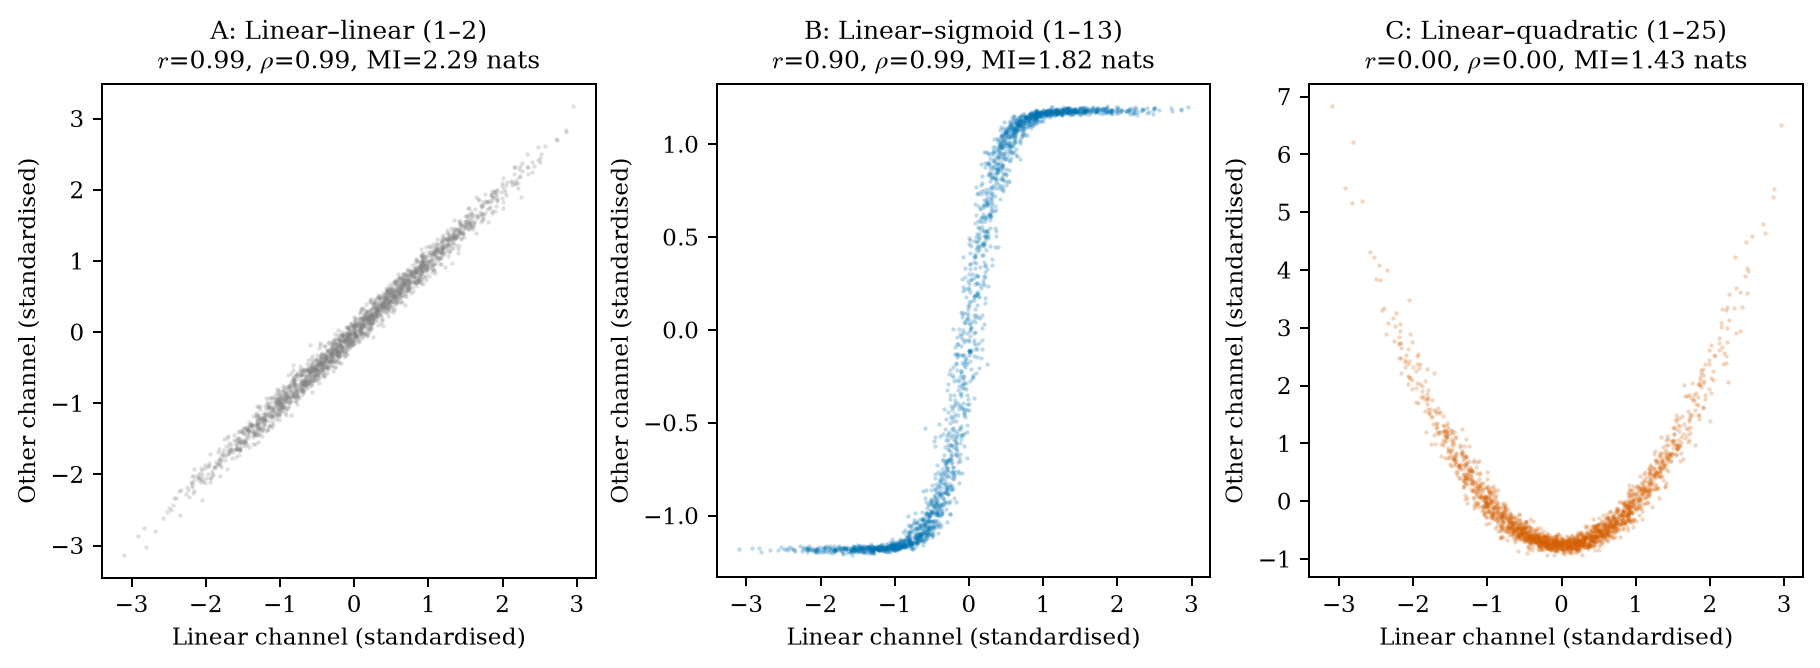

In [3]:
fig = plot_rmi_channel_pairs(frame, OUT, label_edges=True)
plt.show()

For each recording, $z_{ab}=\mathrm{corr}_{i<j}(A^{(a)}_{ij},A^{(b)}_{ij})$. This measures linear agreement between SPI profiles over unique unordered channel pairs. Channel pairs within one recording are dependent; the independent replication unit is the MTS instance. Constant profiles have undefined $z$. MI is KSG with $k=4$, in nats throughout; no Linfoot transform enters $z$. For bivariate Gaussian pairs, $\mathrm{MI}=-\tfrac12\log(1-r^2)$, so even the linear baseline need not have $z_{r,\mathrm{MI}}=1$.

These SPI–SPI planes use predetermined instance 0 at beta 5. Grey marks same-family pairs; colours mark L–M, L–Q and M–Q. Each point is one channel pair and each annotation uses all pairs. Independent axis limits reveal the structure; visual slopes across different panels are not comparable.

The matrix heatmaps retain channel order and mark the same family boundaries. The r/rho scales are shared (−1 to 1); MI has its own nats scale. Blank diagonals are self-pairs excluded from z. In the following SPI planes, A/B/C refer to the third row, the same mixed recording inspected above.

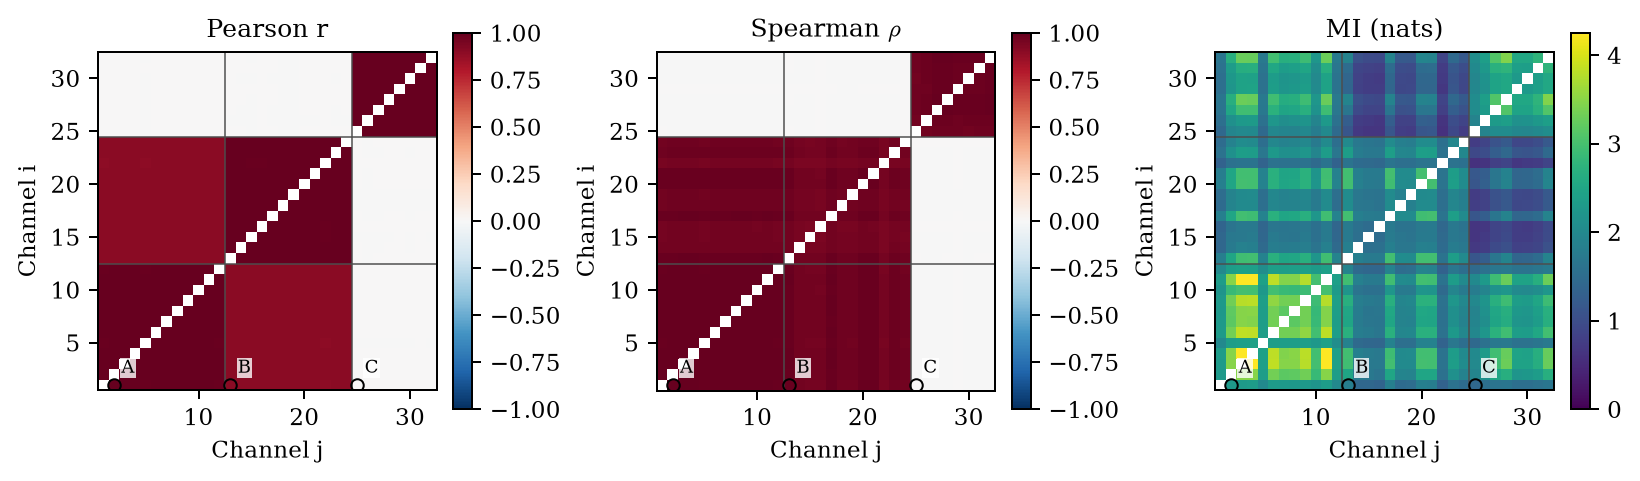

In [4]:
fig = plot_rmi_matrices(frame, OUT)
plt.show()

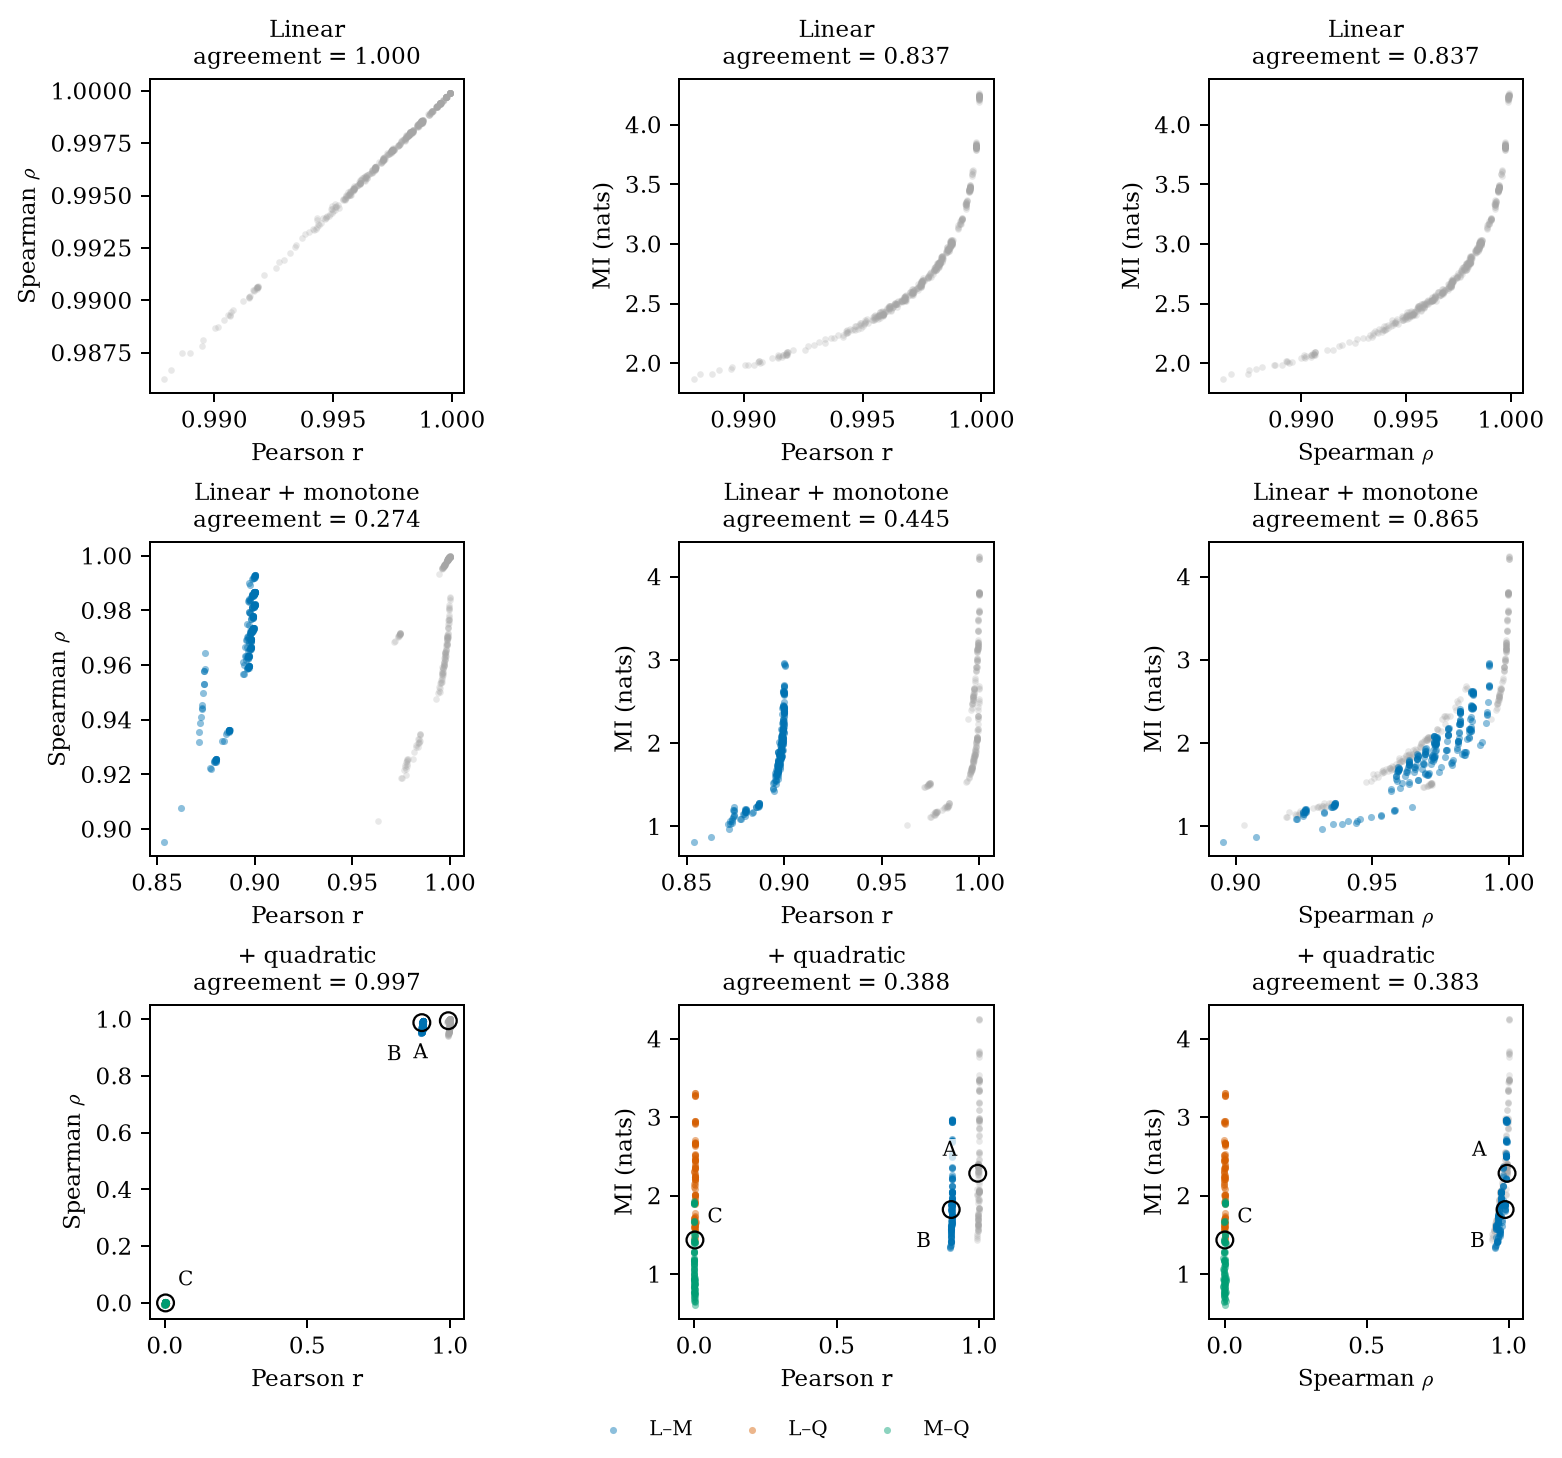

In [5]:
fig = plot_spi_planes(frame, 'r-rho-mi', OUT, highlight_edges=True)
plt.show()

Rainclouds show 50 independent recordings per condition, with descriptive densities and median bars. Each SPI pair has its own y-scale, shared across all three beta columns and all mixtures. The all-linear distribution is repeated for comparison, not additional evidence. Compare numerical ticks, not apparent vertical separation across rows.

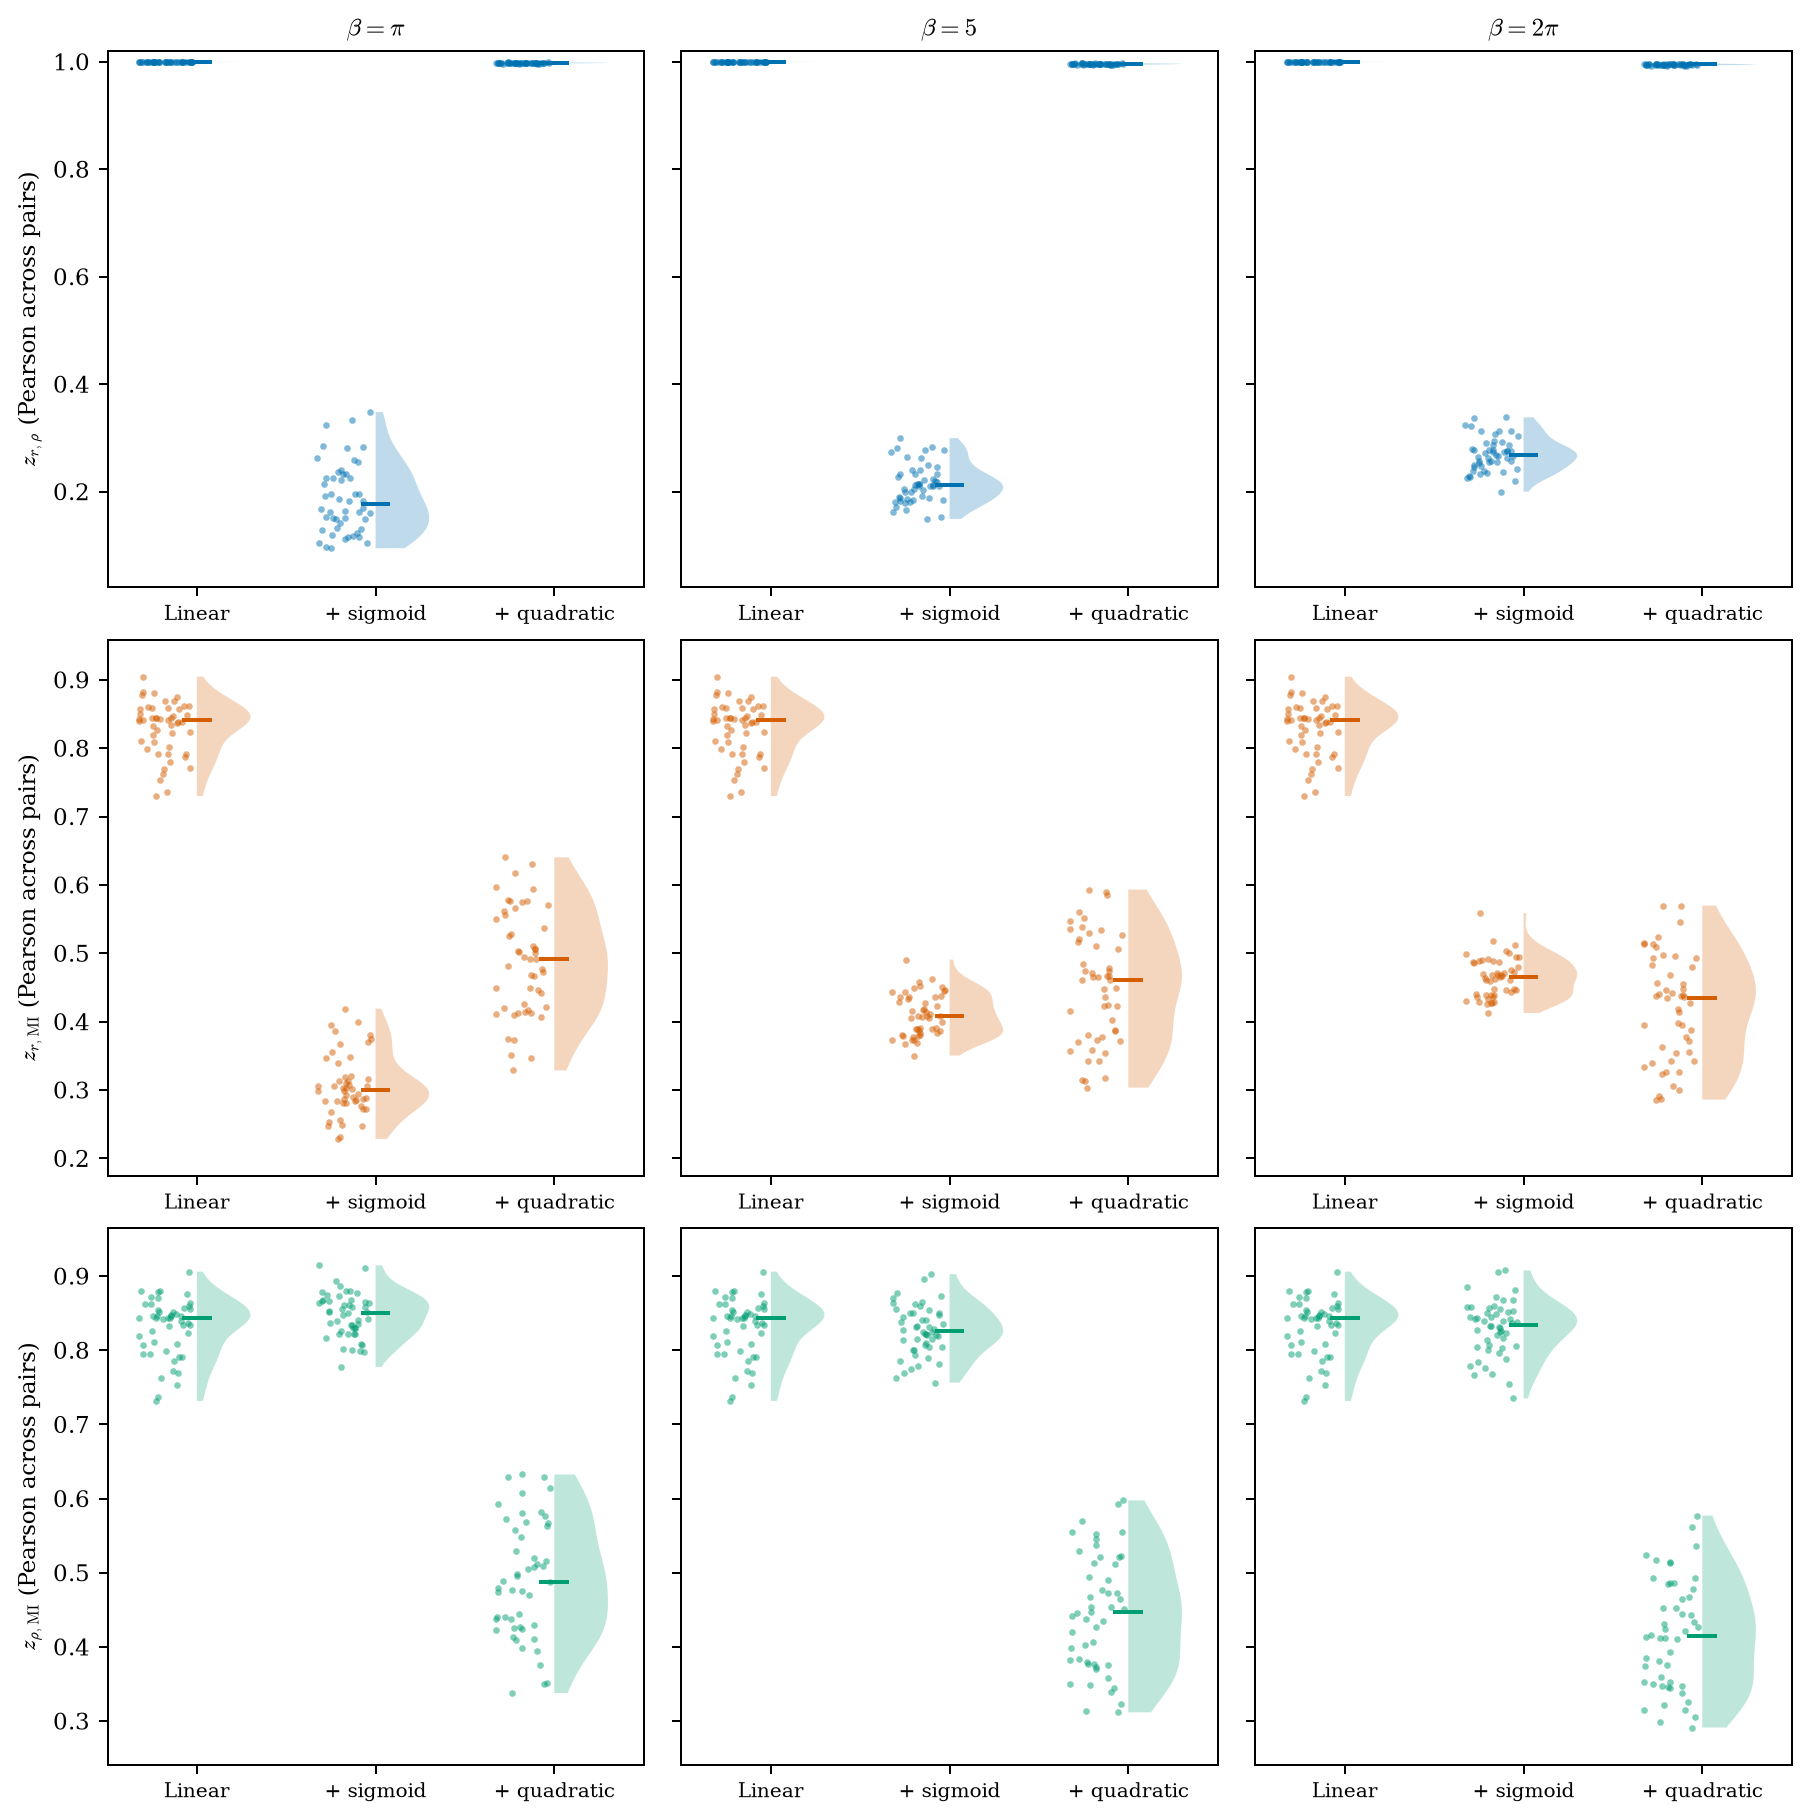

In [6]:
fig = plot_pair_rainclouds(frame, OUT)
plt.show()

The linear/sigmoid mixture reduces r–rho agreement, but increasing beta is not a monotonic dial here: mean agreement is approximately 0.188, 0.215 and 0.270 at pi, 5 and 2pi. Adding quadratic channels changes both relationship shapes and the proportions of pair types. Any renewed r–rho agreement therefore describes this mixture; it does not prove that two insensitive statistics must recouple. A more isolated follow-up would fix channel composition and vary a continuous transform while retaining pair-type colouring.

Why does r–rho agreement return near one after adding quadratic channels? Decompose the empirical covariance over pair types $G\in\{LL,LM,LQ,MM,MQ,QQ\}$:

$$z_{r,\rho}=\frac{\sum_g p_g\,\mathrm{Cov}(r,\rho\mid g)}{s_r s_\rho}+\frac{\mathrm{Cov}_g(\bar r_g,\bar\rho_g)}{s_r s_\rho}.$$

The second covariance weights group centroids by their pair proportions $p_g$. This is an exact decomposition of the same z, not a new estimator or an independence assumption. Means and pointwise 95% Student-t intervals below use 50 MTS instances per mixture at beta 5. The components add to the total for every recording; the analysis checks that identity numerically.

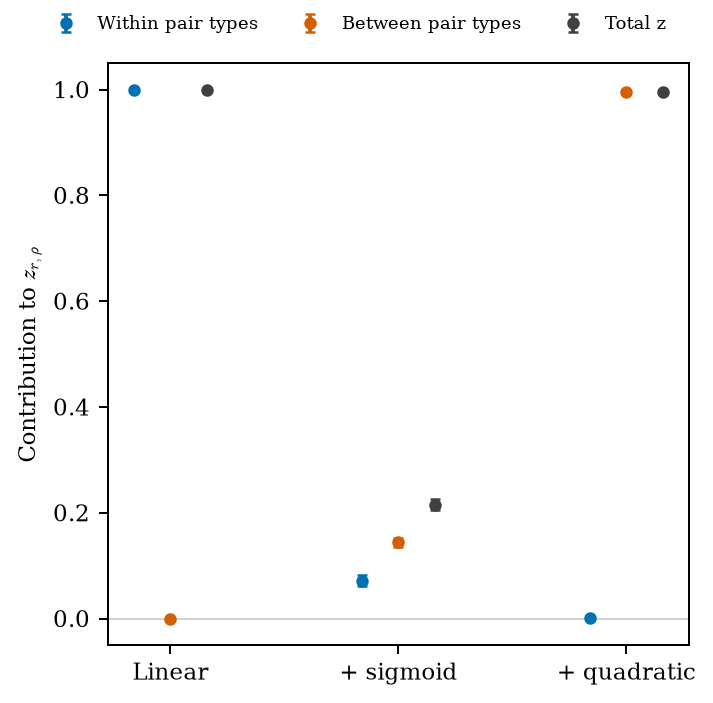

In [7]:
composition = analyze_rmi_composition(frame, OUT)
fig = plot_rmi_composition(composition, OUT)
plt.show()

In the mixed L/M/Q recordings, the mean within-type contribution is 0.00022 and the between-type contribution is 0.99549, giving total z≈0.99571. Thus the near-one agreement is overwhelmingly a contrast between pair-family centroids: both statistics place folded and unfolded relationships into similar broad groups. It is not evidence that they agree strongly within every pair type. In the L/M mixture the contributions are 0.07153 and 0.14390, summing to 0.21542. These values describe this construction, including its noise and mixture proportions.

Temporal-exclusion sensitivity is a supporting check. The AUTO KSG variant excludes temporally close neighbours using pyspi's pair-specific window. Ordinary KSG remains primary. This tests sensitivity to serial dependence, not estimator unbiasedness. The plotted differences are paired within each recording; the all-linear baseline is omitted from this beta comparison. [KSG reference](https://arxiv.org/abs/cond-mat/0305641).

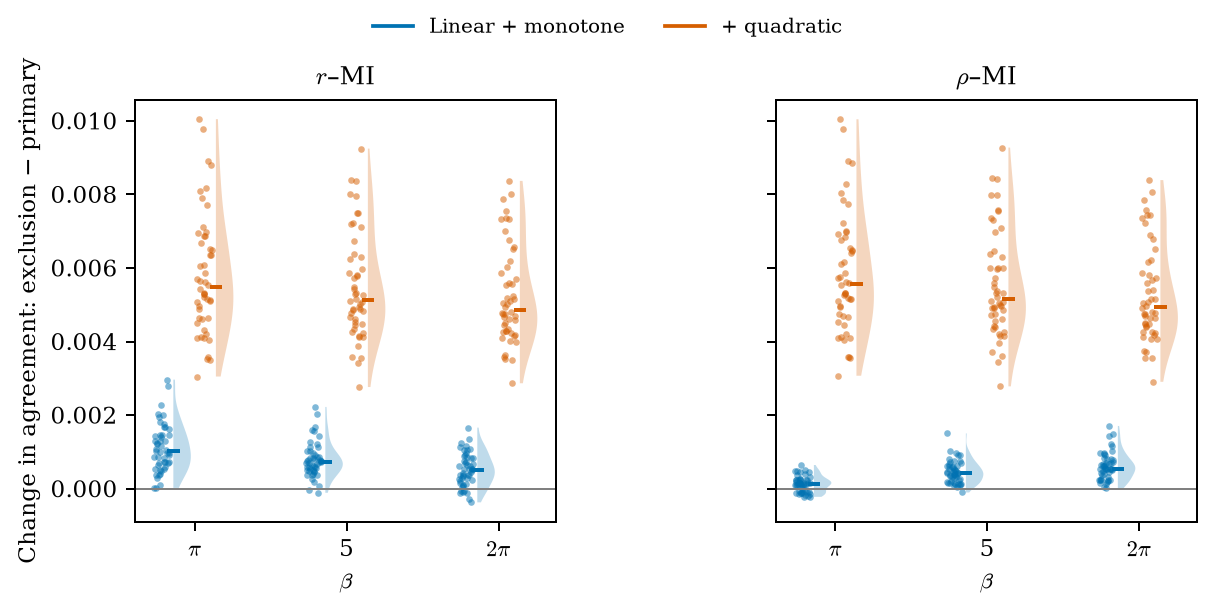

In [8]:
fig = plot_mi_sensitivity(frame, OUT)
plt.show()

Across all 350 recordings, the median absolute changes in r–MI and rho–MI agreement are approximately 0.0013 and 0.0007; the largest is 0.0101. The qualitative pattern survives. Configuration: `research/cases/r_rho_mi/configs/260924_beta.yaml`; SPI definitions: `research/cases/r_rho_mi/spis/r_rho_mi_260924.yaml`. Figures and audits are saved under `results/cases/r-rho-mi-261015/`.